# 01 — GWOSC data, whitening and noise validation

**Author:** Giacomo Moretti · *Statistics and Data Analysis*, Università di Milano-Bicocca, A.Y. 2025–2026

**What this notebook does**

1. Lists the eight 4096 s chunks of LIGO-Hanford (H1) strain from the first observing run (O1), chosen from the public
   GWOSC data far from every catalogued event (selection in `download_data.py`).
2. Estimates the noise PSD of each chunk (median-averaged Welch) and whitens + band-passes the data to 30–500 Hz.
3. Cuts the whitened data into non-overlapping **1 s analysis windows** (1024 samples) — the unit of all later analyses.
4. **Validates the Gaussian-noise hypothesis** that the frequentist and Bayesian likelihoods of notebooks 03–04 rely on:
   bin variances, correlations, tails, stationarity across epochs.
5. Defines the train / validation / test split (by chunk, never by window).

**What it does not do**: no signal, no injection, no detection statistic (notebook 02 onwards). **No window is discarded**:
glitches are part of the noise the detection statistics have to cope with.

> Convention used everywhere (see `gwosc_tools.py`): for stationary Gaussian noise the whitened frequency bins
> $V_k=\mathrm{rfft}(v)_k/\sqrt{512}$ have $\mathrm{Re}\,V_k,\ \mathrm{Im}\,V_k\sim\mathcal N(0,1)$ in the band, so
> the optimal SNR of a signal is simply $\rho^2=\sum_k |h_k|^2$.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import gwosc_tools as g
from gwpy.time import from_gps
g.style()
meta = g.chunks()
print(len(meta), "chunks of", meta[0]["duration"], "s")

8 chunks of 4096 s


## 1. The chunks

The chunks are spread over the whole run (September 2015 – January 2016), so that the test chunks come from detector
epochs the PSD estimate and the thresholds have never seen. The three O1 events (GW150914, GW151012, GW151226) and the
candidate LVT151116/151008 are at least 2000 s away from every chunk.

In [2]:
from gwosc import datasets
events = {e: datasets.event_gps(e) for e in ["GW150914-v3", "GW151012-v3", "GW151226-v3", "151008-v1", "151116-v1"]}
rows = []
for i, m in enumerate(meta):
    s = m["gps_start"]
    split = [k for k, idx in g.SPLIT.items() if i in idx][0]
    dmin = min(abs(s + 2048 - t) for t in events.values()) - 2048
    rows.append(dict(chunk=i, gps_start=s, utc=str(from_gps(s))[:16], split=split, min_dist_to_event_s=int(dmin)))
tab = pd.DataFrame(rows); tab

,chunk,gps_start,utc,split,min_dist_to_event_s
0,0,1126076416,2015-09-12 06:59,train,178950
1,1,1128009728,2015-10-04 16:01,val,334750
2,2,1129295872,2015-10-19 13:17,train,616971
3,3,1130975232,2015-11-07 23:46,test,769597
4,4,1132707840,2015-11-28 01:03,train,958914
5,5,1134329856,2015-12-16 19:37,val,802398
6,6,1135579136,2015-12-31 06:38,train,442785
7,7,1137246208,2016-01-19 13:43,test,2109857


## 2. PSD of each chunk

The PSD is estimated with Welch's method (4 s Hann segments, 0.25 Hz resolution) using the **median** average, which
is robust to the loud glitches that would bias the mean. Each chunk is whitened with **its own** PSD.

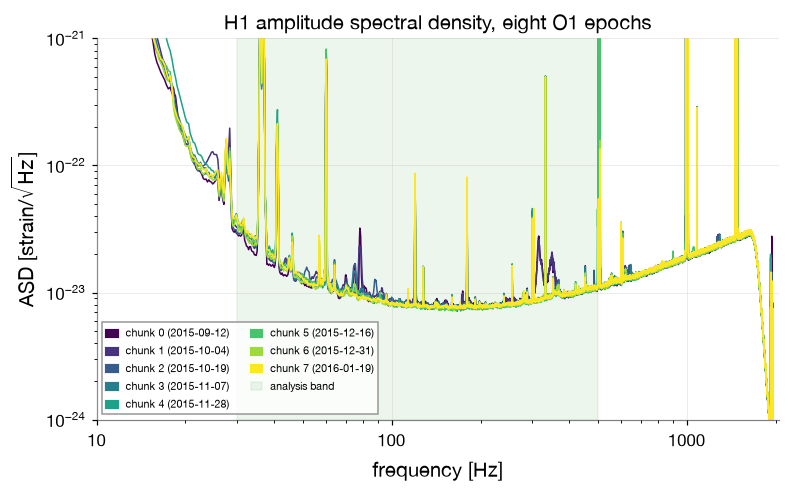

In [3]:
data = [g.load_chunk(i) for i in range(len(meta))]      # builds and caches the whitened windows
fig, ax = plt.subplots(figsize=(8, 4.5))
cm = plt.cm.viridis(np.linspace(0, 1, len(meta)))
for i, d in enumerate(data):
    ax.loglog(d["f_psd"], np.sqrt(d["S"]), color=cm[i], lw=1, label=f"chunk {i} ({tab.utc[i][:10]})")
ax.axvspan(*g.FBAND, color="green", alpha=0.07, label="analysis band")
ax.set_xlim(10, 2048); ax.set_ylim(1e-24, 1e-21)
ax.set_xlabel("frequency [Hz]"); ax.set_ylabel(r"ASD [strain/$\sqrt{\rm Hz}$]")
ax.legend(fontsize=7, ncol=2); ax.set_title("H1 amplitude spectral density, eight O1 epochs")
g.savefig(fig, "fig01_asd_chunks"); plt.show()

In [4]:
# In-band sensitivity of each chunk: "burst range" proxy = 1/sqrt(int df/S) and its change relative to chunk 0
band = g.BAND
inv = np.array([np.sum(1.0 / d["S1"][band]) for d in data])
rel = np.sqrt(inv / inv[0])
print("relative in-band sensitivity (chunk 0 = 1):", np.round(rel, 2))

relative in-band sensitivity (chunk 0 = 1): [1.   1.   1.04 1.06 1.05 1.07 1.06 1.05]


## 3. Whitening

Dividing the Fourier transform by $\sqrt{S_n(f)}$ flattens the spectrum; the band-pass removes the seismic wall below 30 Hz
and the quantisation/violin region above 500 Hz. After down-sampling to 1024 Hz the series is already **unit-variance
in the band** by construction (it is not forced: the check below is an actual test of the PSD estimate).

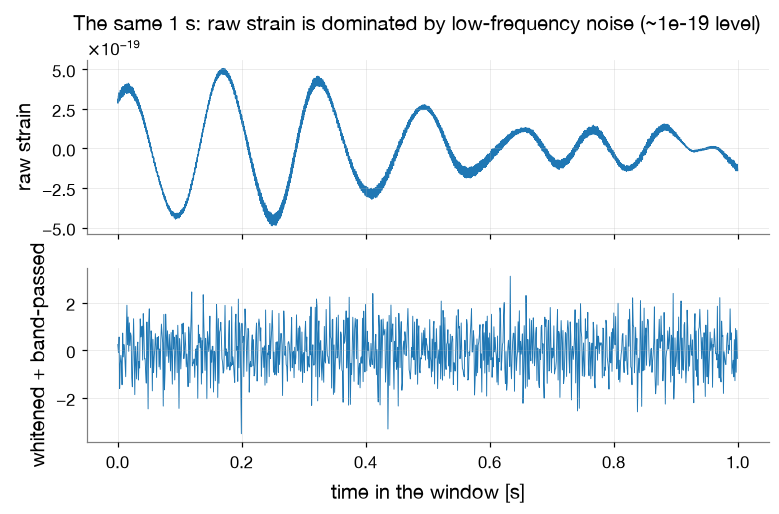

raw strain std = 2.13e-19   whitened std = 0.998


In [5]:
x = np.load("cache/raw/" + meta[0]["file"])
v0 = data[0]["v"]
t = np.arange(g.NWIN) / g.FS
k = 1500                                              # an arbitrary window
fig, ax = plt.subplots(2, 1, figsize=(8, 4.5), sharex=True)
ax[0].plot(np.arange(4096) / 4096, x[k * 4096 + 20 * 4096: k * 4096 + 21 * 4096], lw=.6, color=g.COLORS["H1"])
ax[0].set_ylabel("raw strain")
ax[1].plot(t, v0[k], lw=.6, color=g.COLORS["H1"]); ax[1].set_ylabel("whitened + band-passed")
ax[1].set_xlabel("time in the window [s]")
fig.suptitle("The same 1 s: raw strain is dominated by low-frequency noise (~1e-19 level)")
g.savefig(fig, "fig01_raw_vs_white"); plt.show()
print("raw strain std = %.2e   whitened std = %.3f" % (x[20*4096+k*4096: 21*4096+k*4096].std(), v0[k].std()))

## 4. Is the noise Gaussian and stationary?

The likelihood used in the frequentist and Bayesian analyses assumes that the whitened frequency bins are independent
$\mathcal N(0,1)$ variables. We test it directly on the real data and compare with a **Gaussian reference**: synthetic windows
produced by the same bin→series chain from ideal N(0,1) bins.

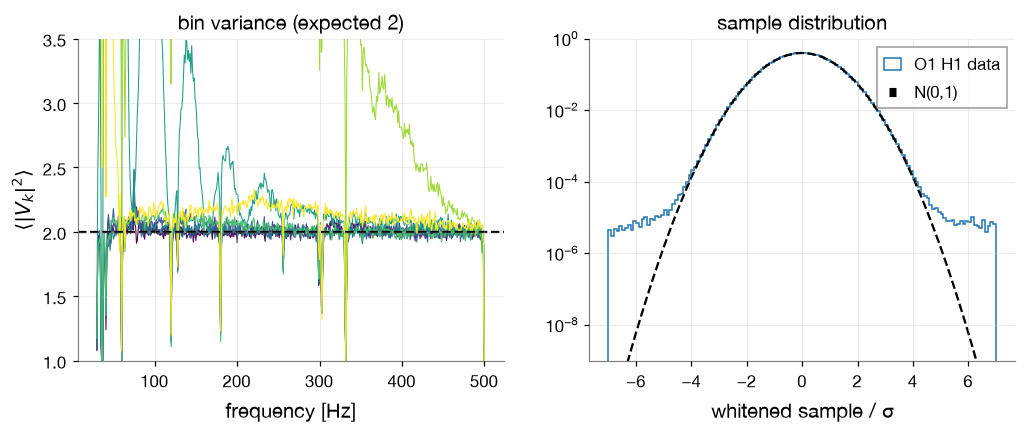

pooled robust sigma = 0.9515 (plain std = 1.125), excess kurtosis = 49710.3
fraction |v|>5σ: data 1.01e-04   Gaussian 5.73e-07


In [6]:
rng = np.random.default_rng(2026)
V_ref = (rng.normal(size=(20000, g.NB)) + 1j * rng.normal(size=(20000, g.NB))) * g.BAND
v_ref = g.to_series(V_ref)

# (a) bin variance per chunk
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for i, d in enumerate(data):
    P = np.mean(np.abs(g.to_bins(d["v"])[:, band]) ** 2, axis=0)
    ax[0].plot(g.FREQ[band], P, color=cm[i], lw=.7)
ax[0].axhline(2, color="k", ls="--"); ax[0].set_ylim(1, 3.5)
ax[0].set_xlabel("frequency [Hz]"); ax[0].set_ylabel(r"$\langle |V_k|^2\rangle$"); ax[0].set_title("bin variance (expected 2)")

# (b) distribution of the samples
allv = np.concatenate([d["v"].ravel() for d in data])
sd = 1.4826 * np.median(np.abs(allv - np.median(allv)))          # robust sigma (glitches inflate the plain std)
bins = np.linspace(-7, 7, 141)
ax[1].hist(allv / sd, bins=bins, density=True, histtype="step", color=g.COLORS["H1"], label="O1 H1 data")
ax[1].plot(bins, stats.norm.pdf(bins), "k--", label="N(0,1)")
ax[1].set_yscale("log"); ax[1].set_ylim(1e-9, 1); ax[1].set_xlabel("whitened sample / σ"); ax[1].legend()
ax[1].set_title("sample distribution")
g.savefig(fig, "fig01_gaussianity"); plt.show()
print("pooled robust sigma = %.4f (plain std = %.3f), excess kurtosis = %.1f" % (sd, allv.std(), stats.kurtosis(allv[::7])))
print("fraction |v|>5σ: data %.2e   Gaussian %.2e" % (np.mean(np.abs(allv) > 5 * sd), 2 * stats.norm.sf(5)))

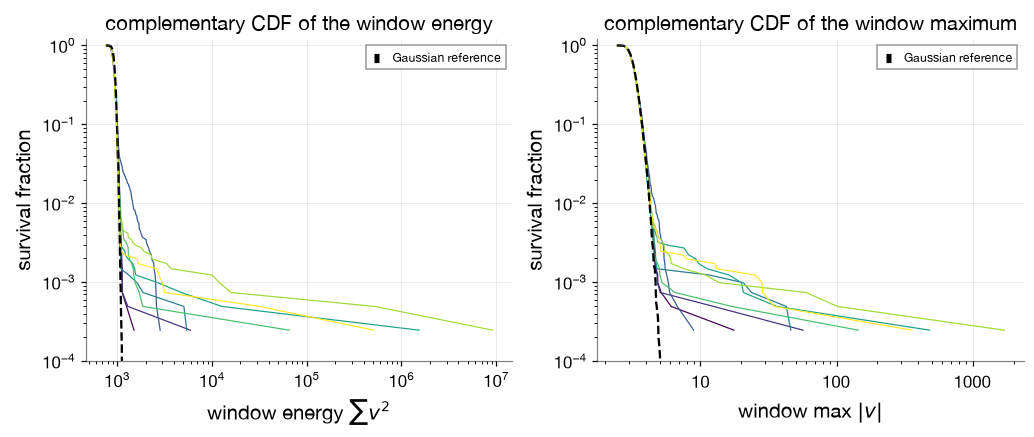

,n_windows,std,frac_E_above_ref_q999,frac_max_above_6
0,4056.0,0.952378,0.003945,0.000493
1,4056.0,0.953998,0.005424,0.000493
2,4056.0,0.958050,0.034763,0.000493
3,4056.0,0.952808,0.001972,0.001233
4,4056.0,1.130131,0.003945,0.002712
5,4056.0,0.959531,0.008629,0.000740
6,4056.0,1.803328,0.006657,0.001972
7,4056.0,1.017179,0.002712,0.002219


In [7]:
# (c) window-level statistics: energy and maximum, data against the Gaussian reference
def wstats(v):
    return dict(E=np.sum(v.astype(float) ** 2, axis=1), amax=np.max(np.abs(v), axis=1))
S_ref = wstats(v_ref)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for key, a, lab in (("E", ax[0], "window energy $\\sum v^2$"), ("amax", ax[1], "window max $|v|$")):
    for i, d in enumerate(data):
        s = wstats(d["v"])[key]
        xs = np.sort(s); a.plot(xs, 1 - np.arange(len(xs)) / len(xs), color=cm[i], lw=.8)
    xs = np.sort(S_ref[key]); a.plot(xs, 1 - np.arange(len(xs)) / len(xs), "k--", lw=1.5, label="Gaussian reference")
    a.set_xscale("log"); a.set_yscale("log"); a.set_xlabel(lab); a.set_ylabel("survival fraction"); a.legend(fontsize=8); a.set_ylim(1e-4, 1.2)
ax[0].set_title("complementary CDF of the window energy"); ax[1].set_title("complementary CDF of the window maximum")
g.savefig(fig, "fig01_window_tails"); plt.show()

summ = {}
for i, d in enumerate(data):
    s = wstats(d["v"])
    summ[i] = dict(n_windows=len(d["v"]), std=float(d["v"].std()),
                   frac_E_above_ref_q999=float(np.mean(s["E"] > np.quantile(S_ref["E"], .999))),
                   frac_max_above_6=float(np.mean(s["amax"] > 6)))
pd.DataFrame(summ).T

What the three panels say:

* **Bulk**: the whitened samples follow N(0,1) down to a probability of ~10⁻⁴ (≈4σ), and the bin variance is 2 within a few per cent in the quiet epochs.
* **Spectral lines and non-stationarity**: the bin variance dips at the 60 Hz harmonics (the median-Welch PSD slightly over-estimates narrow lines at 1 Hz
  resolution) and shows broad excess power in the glitchier epochs (e.g. chunks 4 and 6), i.e. the noise there is not stationary within the 4096 s used to estimate the PSD.
* **Tails**: a fraction ≈10⁻⁴ of the samples lies beyond 5σ (Gaussian: 6·10⁻⁷) and the loudest windows reach hundreds of σ — **glitches**.
  The window-energy and window-maximum distributions leave the Gaussian reference at survival fractions of a few 10⁻² (energy) and 10⁻³ (maximum), by an amount that depends on the epoch.

This is why the thresholds of notebook 03 are set on *real* background, not on the $\chi^2$ expectation, and why the false-alarm calibration is tested on chunks the
threshold has not seen.

## 5. Correlation between bins and between consecutive windows

In [8]:
# quiet windows only (energy below the chunk's 95th percentile): a loud glitch correlates all its bins by itself
Vall = np.concatenate([g.to_bins(d["v"][np.sum(d["v"].astype(float)**2, axis=1) < np.quantile(np.sum(d["v"].astype(float)**2, axis=1), .95)][:2000])[:, band] for d in data])
c_adj = np.mean([np.abs(np.mean(Vall[:, j] * np.conj(Vall[:, j + 1])) / np.sqrt(np.mean(abs(Vall[:, j])**2) * np.mean(abs(Vall[:, j+1])**2))) for j in range(Vall.shape[1] - 1)])
print("mean |correlation| of adjacent bins : %.4f  (statistical floor ~ %.4f)" % (c_adj, 1 / np.sqrt(len(Vall))))
E = [np.sum(d["v"].astype(float) ** 2, axis=1) for d in data]
ac = [np.corrcoef(e[:-1], e[1:])[0, 1] for e in E]
print("lag-1 autocorrelation of the window energy per chunk:", np.round(ac, 3))

mean |correlation| of adjacent bins : 0.0124  (statistical floor ~ 0.0079)
lag-1 autocorrelation of the window energy per chunk: [0.24  0.102 0.797 0.057 0.009 0.008 0.058 0.062]


## 6. Split and summary

The split is **by chunk**, interleaved in time so that every part covers the whole run:

| set | chunks | use |
|---|---|---|
| train | 0, 2, 4, 6 | thresholds, template banks, ML training |
| val | 1, 5 | hyper-parameters, early stopping |
| test | 3, 7 | everything reported as a final number |

In [9]:
sizes = {k: int(sum(len(data[i]["v"]) for i in idx)) for k, idx in g.SPLIT.items()}
print("windows per split:", sizes)
print("chunk energy outliers (plain std per chunk):", {i: round(summ[i]["std"], 2) for i in summ})
g.save_json({"split_windows": sizes, "chunks": tab.to_dict("records"),
             "rel_sensitivity": rel.tolist(), "per_chunk": summ,
             "pooled": {"robust_sigma": float(sd), "plain_std": float(allv.std()), "excess_kurtosis": float(stats.kurtosis(allv[::7])),
                        "frac_above_5sigma": float(np.mean(np.abs(allv) > 5 * sd)),
                        "gauss_frac_above_5sigma": float(2 * stats.norm.sf(5))},
             "adjacent_bin_corr": float(c_adj), "energy_lag1_autocorr": ac}, "01_summary.json")

windows per split: {'train': 16224, 'val': 8112, 'test': 8112}
chunk energy outliers (plain std per chunk): {0: 0.95, 1: 0.95, 2: 0.96, 3: 0.95, 4: 1.13, 5: 0.96, 6: 1.8, 7: 1.02}


## Output and next step

* `cache/win_<gps>.npz` — whitened 1 s windows and PSDs of every chunk (cache, not tracked).
* `results/01_summary.json`, `figures/fig01_*` — numbers and figures quoted in the report.

Next: **`02_waveforms_and_injections.ipynb`** — the three burst morphologies, their exact whitened Fourier transforms, the
analytic SNR and the validation of the injection chain.